# 🚀 Keras-a Giriş: Dərin Öyrənmənin Yüksək Səviyyəli (High-Level) API-si

---

### Keras Nədir və Niyə Lazımdır?

Əvvəlki notebookda (`Tensorflow.ipynb`) gördük ki, xalis TensorFlow ilə neyron şəbəkəsi qurmaq üçün çəkiləri ($W$) və meyil/biasları ($b$) əllə yaratmaq, matris vurmalarını (`tf.matmul`) bir-bir yazmaq, `tf.GradientTape` ilə qradiyentləri hesablayıb optimizatora ötürmək lazım idi (**Low-Level / Aşağı səviyyəli yanaşma**).

**Keras** isə TensorFlow üzərində işləyən yüksək səviyyəli (**High-Level**) interfeysdir:
* 🧱 **Lego Blokları Kimi Sadə:** Mürəkkəb riyaziyyatı hazır qatlar (`Dense`, `Dropout`, `Conv2D`) və hazır metodlar (`model.compile()`, `model.fit()`, `model.evaluate()`) şəklində təqdim edir.
* ⚡ **Sürətli və Rahat:** Kodu qat-qat qısa, oxunaqlı edir və hiperparametrləri sazlamağı (tuning) xeyli asanlaşdırır.
* 🛡️ **Səhvlərdən Qoruyur:** Ölçülərin uyğunluğunu (shape mismatch) və arxaya yayılmanı (backpropagation) pərdəarxasında avtomatik həll edir.

İndi gəlin həmin **MNIST** əlyazma rəqəmlərini tanıyan çoxqatlı perseptron (MLP) şəbəkəsini Keras ilə quraq və fərqi öz gözlərimizlə görək!

İlk növbədə bizə lazım olacaq modulları layihəyə daxil edirik:

In [2]:
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.layers import Input

import matplotlib.pyplot as plt

## 📦 MNIST Verilənlər Bazasının Yüklənməsi

Yenə də klassik **MNIST** bazasından istifadə edirik:
* **60,000 nümunə** — Təlim (Training) üçün ayrılır.
* **10,000 nümunə** — Modelin biliyini yoxlamaq (Test) üçün kənarda saxlanılır.
* Hər bir şəkil $28 \times 28$ piksel ölçülü ağ-qara əlyazma rəqəmidir (0-dan 9-a qədər).

In [6]:
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = mnist.load_data()

print(mnist_train_images.shape)
print(mnist_test_images.shape)
print(mnist_train_labels.shape)
print(mnist_test_labels.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


## 🛠️ Verilənlərin Hazırlanması (Preprocessing): Düzləşdirmə və Normallaşdırma

Keras modelinə ötürməzdən əvvəl şəkilləri müvafiq formata gətirməliyik:

1. **Düzləşdirmə (Flatten):** Hər bir $28 \times 28$ ikiölçülü matrisi 784 elementli ($28 \times 28 = 784$) 1-ölçülü vektora çeviririk (`reshape`). Beləliklə, təlim matrisinin ölçüsü `[60000, 784]`, test matrisinin ölçüsü `[10000, 784]` olur.
2. **Tip Çevrilməsi (`float32`):** Neyron şəbəkəsində çəkilər kəsr ədədlərlə vurulduğu üçün tam ədəd (integer) pikselləri `float32` tipinə çeviririk.
3. **Normallaşdırma (255-ə bölmə):** Piksel parlaqlığı 0 ilə 255 arasındadır. Bütün qiymətləri 255-ə bölərək `[0.0, 1.0]` diapazonuna sıxırıq.
   * *Niyə?* Bu, qradiyentlərin sabit qalmasını təmin edir, çəkilərin partlamasının (*Exploding Gradients*) qarşısını alır və təlim prosesini qat-qat sürətləndirir!

In [8]:
# 1. Şəkilləri 1-ölçülü 784 piksellik vektorlara düzləşdiririk (flatten)
train_images = mnist_train_images.reshape(60000, 784)
test_images = mnist_test_images.reshape(10000, 784)

test_images.shape

(10000, 784)

In [9]:
# 2. Dəyərləri float32 onluq kəsr tipinə çeviririk
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

# 3. Piksel dəyərlərini [0.0, 1.0] aralığına gətiririk (Normallaşdırma)
train_images /= 255
test_images /= 255

## 🎯 Etiketlərin "One-Hot" Formatına Çevrilməsi

Hədəf rəqəmləri (0-9) neyron şəbəkəsinə adi tam ədədlər kimi verə bilmərik. Əgər modelə 7 rəqəmini ədəd kimi versək, o elə zənn edər ki, 7 rəqəmi 1-dən "7 dəfə böyükdür və ya daha vacibdir". Halbuki bunlar sadəcə fərqli kateqoriyalardır (siniflərdir)!

Bunun qarşısını almaq üçün **One-Hot Encoding** üsulundan istifadə olunur:
* Hər bir rəqəm 10 elementli ikili (binary) vektor kimi təmsil olunur.
* Vektorun bütün elementləri $0$ olur, yalnız həmin rəqəmin indeksindəki element $1$ olur (saymağa 0-dan başlayırıq).
* Məsələn:
  * Rəqəm `1` $\to$ `[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]`
  * Rəqəm `5` $\to$ `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`

Keras-ın `to_categorical` funksiyası etiketləri avtomatik olaraq bu formaya gətirir (`[60000, 10]` ölçülü matris).

In [10]:
# Rəqəm etiketlərini (0-9) 10 ölçülü one-hot vektorlarına çeviririk
train_labels = keras.utils.to_categorical(mnist_train_labels, 10)
test_labels = keras.utils.to_categorical(mnist_test_labels, 10)

test_labels.shape

(10000, 10)

Gəlin hər şeyin qaydasında olduğundan əmin olmaq üçün təlim dəstindən bir nümunə şəkilə və onun one-hot etiket formatına baxaq:

One-hot etiket vektoru: [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]


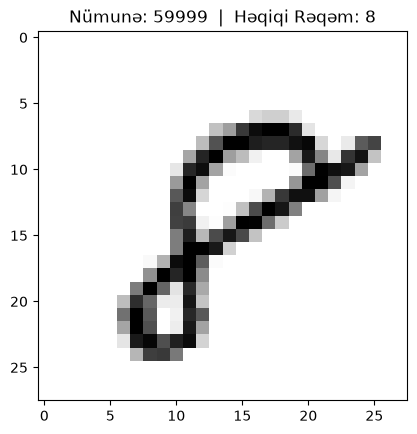

In [ ]:
def display_sample(num):
    # Bu nümunənin one-hot vektorunu çap edirik
    print("One-hot etiket vektoru:", train_labels[num])  
    
    # argmax vasitəsilə 1 olan indeksi (həqiqi rəqəmi) tapırıq
    label = train_labels[num].argmax(axis=0)
    
    # 784 ölçülü vektoru təkrar 28x28 formasına salıb ekranda çəkirik
    image = train_images[num].reshape([28, 28])
    plt.title('Nümunə: %d  |  Həqiqi Rəqəm: %d' % (num, label))
    plt.imshow(image, cmap=plt.get_cmap('gray_r'))
    plt.show()

# 60,000-ci nümunəni nümayiş etdiririk
display_sample(59999)

## 🏗️ Keras İlə Modelin Qurulması: Cəmi Bir Neçə Sətir!

Bax burada Keras-ın əsl gücü və zərifliyi ortaya çıxır!

Xatırlayırsınızsa, əvvəlki dərsdə TensorFlow ilə bu şəbəkəni qurarkən:
* `weights` və `biases` lüğətlərini əllə yaratmışdıq,
* Hər qat üçün `tf.matmul(x, W) + b` yazmışdıq,
* Qradiyentləri lentə yazıb bir-bir tənzimləmişdik.

Keras-da isə bütün bunlar **Lego blokları** kimidir:
1. `Sequential()`: Qatların bir-birinin ardınca düzüldüyü model skeleti yaradır.
2. `Input(shape=(784,))`: Modelin 784 piksel qəbul edəcəyini bildirir.
3. `Dense(512, activation='relu')`: 512 neyronlu tam əlaqəli (Fully Connected) gizli qat. 
   * 🌟 **ReLU (Rectified Linear Unit):** Bu dəfə `sigmoid` əvəzinə müasir dərin öyrənmənin standartı olan `ReLU` istifadə edirik! ReLU qradiyentlərin sönməsinin (*Vanishing Gradient*) qarşısını alır və təlimi inanılmaz dərəcədə sürətləndirir.
4. `Dense(10, activation='softmax')`: 10 çıxış neyronu (hər rəqəm üçün bir neyron). `softmax` bu çıxışları cəmi $1.0$ olan ehtimal paylanmasına çevirir.

In [15]:
# Ardıcıl (Sequential) modelimizi yaradırıq
model = Sequential()

# Giriş qatı: 784 ədəd piksel dəyəri
model.add(Input(shape=(784,)))

# Gizli qat: 512 neyron və ReLU aktivasiya funksiyası
model.add(Dense(512, activation='relu'))

# Çıxış qatı: 10 neyron (0-9 rəqəmləri) və Softmax ehtimal aktivasiyası
model.add(Dense(10, activation='softmax'))

## 📋 Modelin Arxitektura Xülasəsi: `model.summary()`

Keras bizə modelin daxili strukturu, qatların ardıcıllığı və ümumi öyrənilən parametrlərin (çəkilər və biaslar) sayı haqqında aydın xülasə təqdim edir:

In [16]:
# Modelin strukturunu və parametrlər sayını ekrana çıxarırıq
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

### 🧮 Parametrlərin Sayı Necə Hesablanır?
* **1-ci Dense Qatı:** $784 \text{ giriş} \times 512 \text{ neyron} + 512 \text{ bias} = \mathbf{401,920} \text{ parametr}$
* **2-ci Dense Qatı:** $512 \text{ giriş} \times 10 \text{ neyron} + 10 \text{ bias} = \mathbf{5,130} \text{ parametr}$
* **Cəmi öyrənilən parametr:** $\mathbf{407,050}$ ədəd! Model məhz bu 407 min ədədi dəqiqliklə tənzimləyərək əlyazmanı tanımağı öyrənir.

---

## ⚙️ Modelin Kompilyasiyası: Optimizator və İtki Funksiyası

Modeli təlim etməzdən əvvəl üç vacib komponenti təyin edirik (`model.compile`):
1. **İtki Funksiyası (`loss='categorical_crossentropy'`):** One-hot formatlı çoxsinifli təsnifat məsələləri üçün standart seçimdir. Modelin ehtimalları ilə həqiqi etiket arasındakı fərqi logaritmik cəza ilə ölçür.
2. **Optimizator (`optimizer=RMSprop()`):** *Root Mean Square Propagation*. Sadə SGD-dən qat-qat güclüdür; hər bir parametr üçün təlim sürətini son addımların qradiyentlərinə əsasən adaptiv tənzimləyir. Digər məşhur seçimlər: `Adam`, `SGD`, `Nadam`.
3. **Metrika (`metrics=['accuracy']`):** İnsan üçün ən aydın göstərici olan dəqiqlik faizini (düzgün təxminlər / bütün təxminlər) izləyir.

In [18]:
# Modeli itki funksiyası, optimizator və metrika ilə təchiz edirik
model.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(),
              metrics=['accuracy'])

## 🏋️ Modelin Təlim Edilməsi: `model.fit()`

Keras-da təlim prosesi üçün dövrlər (`for epoch in ...`) yazmağa ehtiyac yoxdur. Tək bir `model.fit()` əmri ilə:
* Məlumat partiyalara (`batch_size=100`) bölünür,
* Hər partiyada irəli hesablama aparılır və itki tapılır,
* Geri yayılma ilə qradiyentlər hesablanıb çəkilər yenilənir,
* Hər epoch sonunda test dəsti (`validation_data`) üzrə keyfiyyət ölçülür!

Biz **10 epoch** (bütün 60,000 şəklin modeldən 10 dəfə keçməsi) təyin edirik.

In [19]:
# Modeli 10 dövr (epoch) ərzində təlim edirik
history = model.fit(train_images, train_labels,
                    batch_size=100,
                    epochs=10,
                    verbose=2,
                    validation_data=(test_images, test_labels))

Epoch 1/10
600/600 - 2s - 3ms/step - accuracy: 0.9276 - loss: 0.2513 - val_accuracy: 0.9636 - val_loss: 0.1232
Epoch 2/10
600/600 - 2s - 3ms/step - accuracy: 0.9708 - loss: 0.1003 - val_accuracy: 0.9718 - val_loss: 0.0923
Epoch 3/10
600/600 - 1s - 2ms/step - accuracy: 0.9801 - loss: 0.0658 - val_accuracy: 0.9790 - val_loss: 0.0700
Epoch 4/10
600/600 - 1s - 2ms/step - accuracy: 0.9851 - loss: 0.0482 - val_accuracy: 0.9767 - val_loss: 0.0701
Epoch 5/10
600/600 - 1s - 2ms/step - accuracy: 0.9889 - loss: 0.0354 - val_accuracy: 0.9796 - val_loss: 0.0640
Epoch 6/10
600/600 - 1s - 2ms/step - accuracy: 0.9923 - loss: 0.0268 - val_accuracy: 0.9806 - val_loss: 0.0601
Epoch 7/10
600/600 - 1s - 2ms/step - accuracy: 0.9939 - loss: 0.0201 - val_accuracy: 0.9792 - val_loss: 0.0673
Epoch 8/10
600/600 - 1s - 2ms/step - accuracy: 0.9955 - loss: 0.0156 - val_accuracy: 0.9805 - val_loss: 0.0619
Epoch 9/10
600/600 - 1s - 2ms/step - accuracy: 0.9967 - loss: 0.0117 - val_accuracy: 0.9824 - val_loss: 0.0618
E

## 📊 Yekun Nəticə və Qiymətləndirmə: `model.evaluate()`

Cəmi 10 epoch ərzində Keras modeli test məlumatlarında inanılmaz dərəcədə yüksək nəticə göstərdi!

Gəlin modelin heç vaxt görmədiyi **10,000 test şəkli** üzərində dəqiqliyini və itkisini rəsmi olaraq ölçək:

In [22]:
# Test dəsti üzərində itkini və dəqiqliyi hesablayırıq
score = model.evaluate(test_images, test_labels, verbose=0)
print('Test İtkisi (Loss): %.4f' % score[0])
print('Test Dəqiqliyi (Accuracy): %.2f%%' % (score[1] * 100))

Test İtkisi (Loss): 0.0623
Test Dəqiqliyi (Accuracy): 98.13%


Model təxminən **98% dəqiqlik** əldə etdi! 
Bu, əvvəlki dəftərdə xalis TensorFlow ilə qurduğumuz modelin 93%-lik nəticəsindən xeyli üstündür. Səbəb: Keras-da **ReLU** aktivasiya funksiyası və **RMSprop** adaptiv optimizatorundan istifadə etməyimizdir!

---

## 🔎 Modelin Yanıldığı Şəkillərin Təhlili

Dəqiqlik 98% olduğuna görə, 1000 şəklin içində cəmi təxminən 20 ədəd səhv tapılacaq. Gəlin ilk 1000 test şəklini skan edək və modelin hansı rəqəmlərdə səhv etdiyini, nə dediyini və həqiqi rəqəmin nə olduğunu ekranda araşdıraq:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━

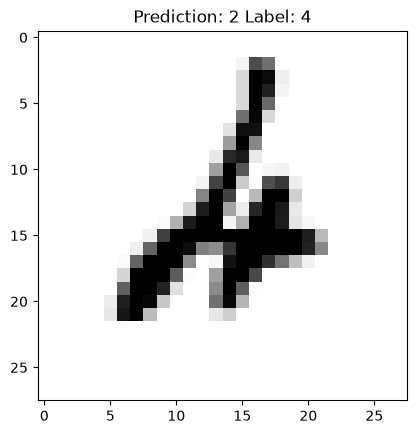

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━

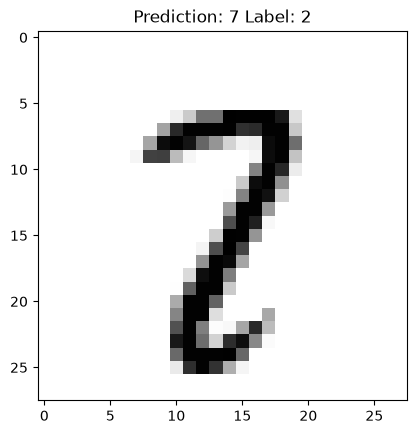

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━

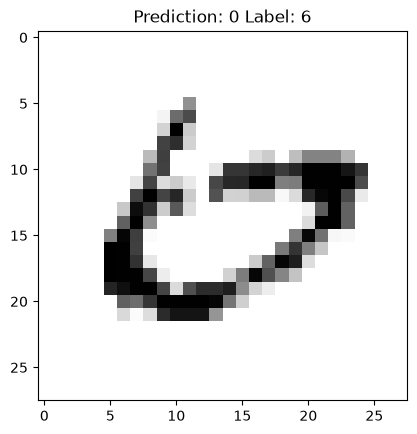

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


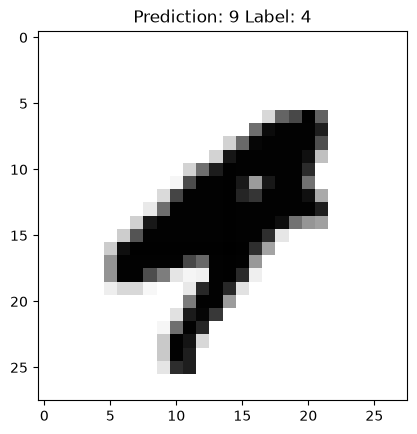

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


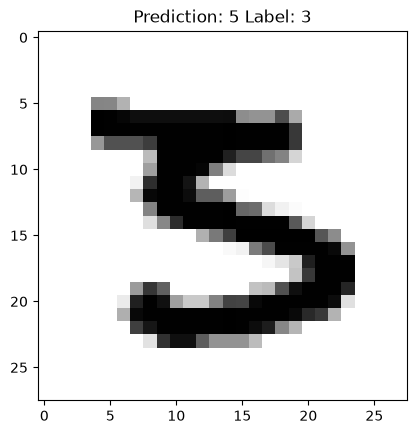

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━

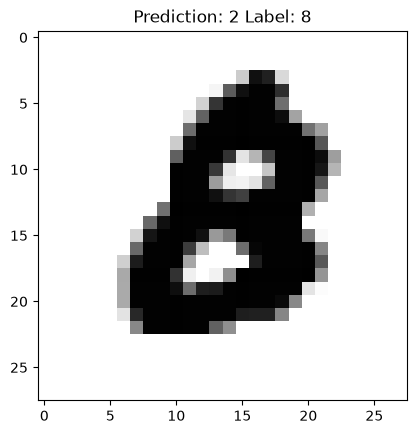

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━

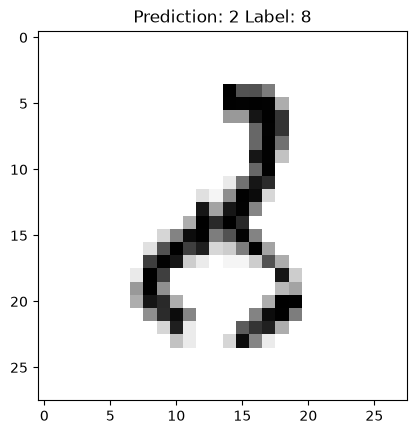

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━

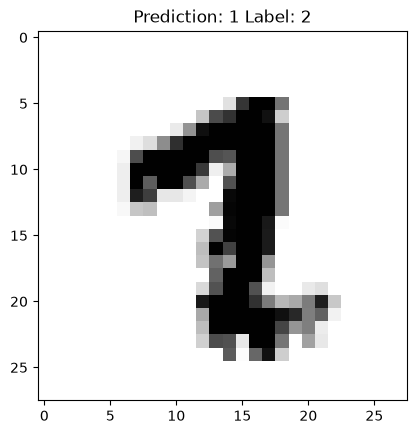

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


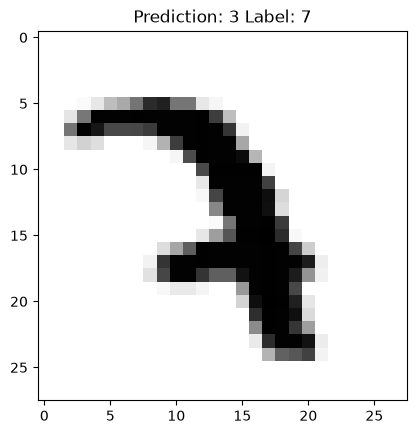

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


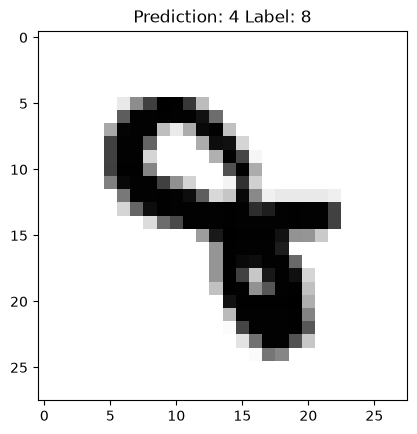

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━

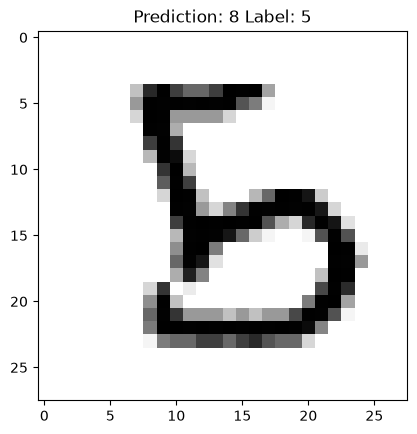

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━

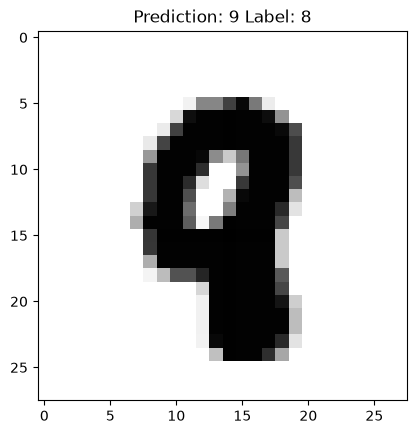

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


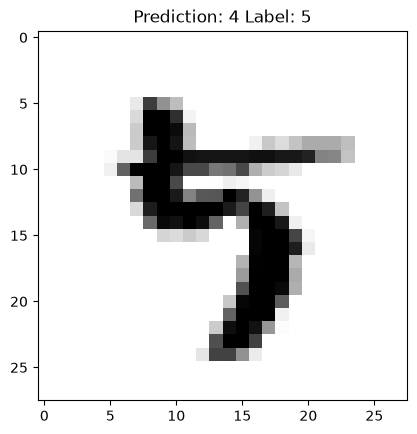

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


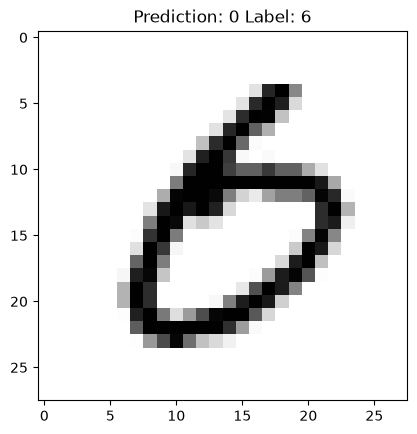

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━

In [11]:
# İlk 1000 test şəkli arasında səhv təxminləri axtarıb göstəririk
for x in range(1000):
    test_image = test_images[x, :].reshape(1, 784)
    # Modelin ən yüksək ehtimal verdiyi rəqəm (proqnoz)
    predicted_cat = model.predict(test_image, verbose=0).argmax()
    # Həqiqi rəqəm etiketi
    label = test_labels[x].argmax()
    
    # Əgər model səhv edibsə, şəkli ekrana çıxarırıq
    if (predicted_cat != label):
        plt.figure(figsize=(2.5, 2.5))
        plt.title('Modelin Təxmini: %d | Həqiqi: %d' % (predicted_cat, label), color='red')
        plt.imshow(test_image.reshape([28, 28]), cmap=plt.get_cmap('gray_r'))
        plt.axis('off')
        plt.show()
        print("Şəkil indeksi: %d" % x)
        print("-" * 35)